# MNIST Dataset Exploration

Week 1 practice by Fayz Liaqat. I used MNIST in CSV from Kaggle because the images have clear labels and are easy to explore.

Dataset: https://www.kaggle.com/datasets/oddrationale/mnist-in-csv

Run python download_data.py in the project folder first. The notebook uses the original training and test files separately.

Each row contains one digit image. The label is the answer, and the other 784 values are pixels. This notebook explores the data and suggests models. It does not train a model.

## 1. Import libraries and load the data

Load the two original files. The test file stays separate.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

try:
    baseDir = Path(__file__).resolve().parent
except NameError:
    baseDir = Path.cwd()

outputDir = baseDir / "outputs"
outputDir.mkdir(exist_ok=True)
df = pd.read_csv(baseDir / "data" / "mnist_train.csv")
testDf = pd.read_csv(baseDir / "data" / "mnist_test.csv")



## 2. Basic queries, like the class practice

These are the same basic Pandas queries used in class. I show statistics for a few columns so the output is readable.

In [2]:
print("First five rows:")
print(df.head())
print("Training shape:", df.shape)
print("Test shape:", testDf.shape)
print("Column information:")
df.info()
print("Statistics for the label and first five pixels:")
print(df.iloc[:, :6].describe())



First five rows:
   label  1x1  1x2  1x3  1x4  1x5  1x6  1x7  1x8  1x9  ...  28x19  28x20  \
0      5    0    0    0    0    0    0    0    0    0  ...      0      0   
1      0    0    0    0    0    0    0    0    0    0  ...      0      0   
2      4    0    0    0    0    0    0    0    0    0  ...      0      0   
3      1    0    0    0    0    0    0    0    0    0  ...      0      0   
4      9    0    0    0    0    0    0    0    0    0  ...      0      0   

   28x21  28x22  28x23  28x24  28x25  28x26  28x27  28x28  
0      0      0      0      0      0      0      0      0  
1      0      0      0      0      0      0      0      0  
2      0      0      0      0      0      0      0      0  
3      0      0      0      0      0      0      0      0  
4      0      0      0      0      0      0      0      0  

[5 rows x 785 columns]
Training shape: (60000, 785)
Test shape: (10000, 785)
Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 t

## 3. Check missing values, duplicates and pixel values

Check data quality before deciding whether cleaning is needed. Repeated rows deserve inspection before removing them.

In [3]:
print("Missing values in training data:", df.isnull().sum().sum())
print("Missing values in test data:", testDf.isnull().sum().sum())
print("Duplicate training rows:", df.duplicated().sum())
print("Duplicate test rows:", testDf.duplicated().sum())
pixelData = df.drop(columns="label")
print("Smallest pixel value:", pixelData.min().min())
print("Largest pixel value:", pixelData.max().max())
print("Labels:", sorted(df["label"].unique()))



Missing values in training data: 0
Missing values in test data: 0


Duplicate training rows: 0


Duplicate test rows: 0


Smallest pixel value: 0
Largest pixel value: 255
Labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


## 4. Ask questions using filters and grouping

Filter rows to answer questions about the digits. Pixel intensity describes the image, not model accuracy.

In [4]:
print("How many training images belong to each digit?")
labelCounts = df["label"].value_counts().sort_index()
print(labelCounts)
print("How many test images belong to each digit?")
print(testDf["label"].value_counts().sort_index())

digitSeven = df[df["label"] == 7]
print("Number of digit 7 images:", len(digitSeven))
print("First three digit 7 rows:")
print(digitSeven.head(3))
print("Number of rows with labels 0 or 1:", len(df[df["label"].isin([0, 1])]))
print("Most common training digit:", labelCounts.idxmax())
print("Least common training digit:", labelCounts.idxmin())

averageBrightness = pixelData.mean(axis=1)
print("Average pixel intensity by digit (0 is black and 255 is white):")
print(averageBrightness.groupby(df["label"]).mean().round(2))
labelCounts.rename("count").to_csv(outputDir / "label_counts.csv")



How many training images belong to each digit?
label
0    5923
1    6742
2    5958
3    6131
4    5842
5    5421
6    5918
7    6265
8    5851
9    5949
Name: count, dtype: int64
How many test images belong to each digit?
label
0     980
1    1135
2    1032
3    1010
4     982
5     892
6     958
7    1028
8     974
9    1009
Name: count, dtype: int64
Number of digit 7 images: 6265
First three digit 7 rows:
    label  1x1  1x2  1x3  1x4  1x5  1x6  1x7  1x8  1x9  ...  28x19  28x20  \
15      7    0    0    0    0    0    0    0    0    0  ...      0      0   
29      7    0    0    0    0    0    0    0    0    0  ...      0      0   
38      7    0    0    0    0    0    0    0    0    0  ...      0      0   

    28x21  28x22  28x23  28x24  28x25  28x26  28x27  28x28  
15      0      0      0      0      0      0      0      0  
29      0      0      0      0      0      0      0      0  
38      0      0      0      0      0      0      0      0  

[3 rows x 785 columns]


Number of rows with labels 0 or 1: 12665
Most common training digit: 1
Least common training digit: 5
Average pixel intensity by digit (0 is black and 255 is white):
label
0    44.22
1    19.38
2    37.99
3    36.09
4    30.95
5    32.83
6    35.01
7    29.20
8    38.29
9    31.26
dtype: float64


## 5. Draw a simple chart

Compare the class counts visually.

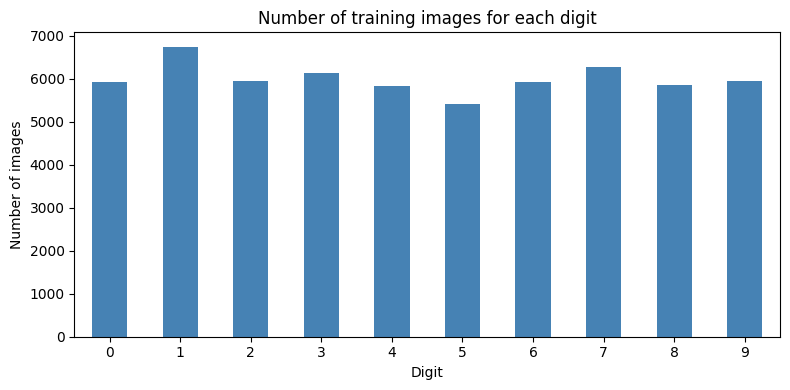

In [5]:
plt.figure(figsize=(8, 4))
labelCounts.plot(kind="bar", color="steelblue", rot=0)
plt.title("Number of training images for each digit")
plt.xlabel("Digit")
plt.ylabel("Number of images")
plt.tight_layout()
plt.savefig(outputDir / "label_counts.png", dpi=150)
plt.show()
plt.close()



## 6. Turn pixel rows back into images

Reshape 784 pixels into a 28 by 28 image. Show one example for each label.

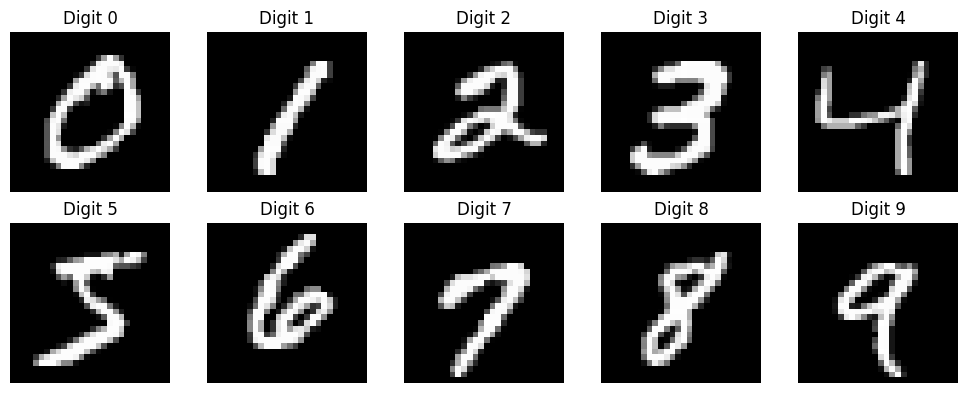

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in enumerate(axes.flat):
    row = df[df["label"] == digit].iloc[0]
    image = row.drop("label").to_numpy().reshape(28, 28)
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Digit {digit}")
    ax.axis("off")
plt.tight_layout()
plt.savefig(outputDir / "sample_digits.png", dpi=150)
plt.show()
plt.close()



## 7. Identify the problem and suitable models

The labels make this supervised classification. KNN is an understandable starting point. A CNN is a later image-focused option. Before training, split the training data into training and validation sets, normalize pixels by dividing by 255, and keep the original test data for final evaluation. Compare accuracy and a confusion matrix.

In [7]:
print("Target: label, the digit from 0 to 9.")
print("Features: the 784 pixel columns, making a 28 x 28 grayscale image.")
print("Learning type: supervised learning because each image has a label.")
print("Task: multiclass classification because there are ten categories.")
print("A simple first model: K-Nearest Neighbors (KNN).")
print("KNN compares an image with similar labeled images.")
print("A later option: a Convolutional Neural Network (CNN) for image patterns.")
print("Unsupervised K-Means could group images if labels were ignored.")
print("Its groups would not automatically be the correct digit labels.")
print("No model is trained in this exploration.")


Target: label, the digit from 0 to 9.
Features: the 784 pixel columns, making a 28 x 28 grayscale image.
Learning type: supervised learning because each image has a label.
Task: multiclass classification because there are ten categories.
A simple first model: K-Nearest Neighbors (KNN).
KNN compares an image with similar labeled images.
A later option: a Convolutional Neural Network (CNN) for image patterns.
Unsupervised K-Means could group images if labels were ignored.
Its groups would not automatically be the correct digit labels.
No model is trained in this exploration.
